# Gold recovery in rougher flotation


In [1]:
import numpy as np 
import math
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression 
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance
from scipy.optimize import linprog

In [2]:
fileName = 'gold_project_2026.csv'
dateColumn = 'date'
df = pd.read_csv(fileName, index_col = dateColumn, parse_dates = [dateColumn])

## Data preprocessing


### Data inspection


In [3]:
# check the overall info about the dataframe 
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8449 entries, 2016-01-15 00:00:00 to 2016-12-31 23:59:00
Data columns (total 29 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Feed_comp_ag[%]               8381 non-null   float64
 1   Feed_comp_pb[%]               8343 non-null   float64
 2   Feed_rate_[ton/h]             8379 non-null   float64
 3   Feed_size_[um]                8114 non-null   float64
 4   Feed_solids[%]                8268 non-null   float64
 5   Feed_comp_au[%]               8381 non-null   float64
 6   Floatbank10_sulfate[g/ton]    8047 non-null   float64
 7   Floatbank10_xanthate [g/ton]  8258 non-null   float64
 8   Concentrate_ag[%]             8381 non-null   float64
 9   Concentrate_pb[%]             8381 non-null   float64
 10  Concentrate_solid[%]          8357 non-null   float64
 11  Concentrate_au[%]             8381 non-null   float64
 12  Recovery[%]                   7367 no

In [4]:
# check the percentage of missingness for each variable
print('Missing data fractions:')
for column_name in list(df.columns):
    missingpercentage = 100 * df[column_name].isnull().sum() / len(df)
    print(f'{missingpercentage:4.1f} % missing in {column_name}')

Missing data fractions:
 0.8 % missing in Feed_comp_ag[%]
 1.3 % missing in Feed_comp_pb[%]
 0.8 % missing in Feed_rate_[ton/h]
 4.0 % missing in Feed_size_[um]
 2.1 % missing in Feed_solids[%]
 0.8 % missing in Feed_comp_au[%]
 4.8 % missing in Floatbank10_sulfate[g/ton]
 2.3 % missing in Floatbank10_xanthate [g/ton]
 0.8 % missing in Concentrate_ag[%]
 0.8 % missing in Concentrate_pb[%]
 1.1 % missing in Concentrate_solid[%]
 0.8 % missing in Concentrate_au[%]
12.8 % missing in Recovery[%]
12.0 % missing in Tailing_ag[%]
 0.8 % missing in Tailings_pb[%]
12.0 % missing in Tailings_solids[%]
12.0 % missing in Tailings_au[%]
 0.3 % missing in Floatbank10_a_air_[m3/h]
 0.3 % missing in Floatbank10_a_level[mm]
 0.3 % missing in Floatbank10_b_air_[m3/h]
 0.3 % missing in Floatbank10_b_level[mm]
 0.3 % missing in Floatbank10_c_air_[m3/h]
 0.2 % missing in Floatbank10_c_level[mm]
 0.3 % missing in Floatbank10_d_air_[m3/h]
 0.2 % missing in Floatbank10_d_level[mm]
 0.3 % missing in Floatbank1

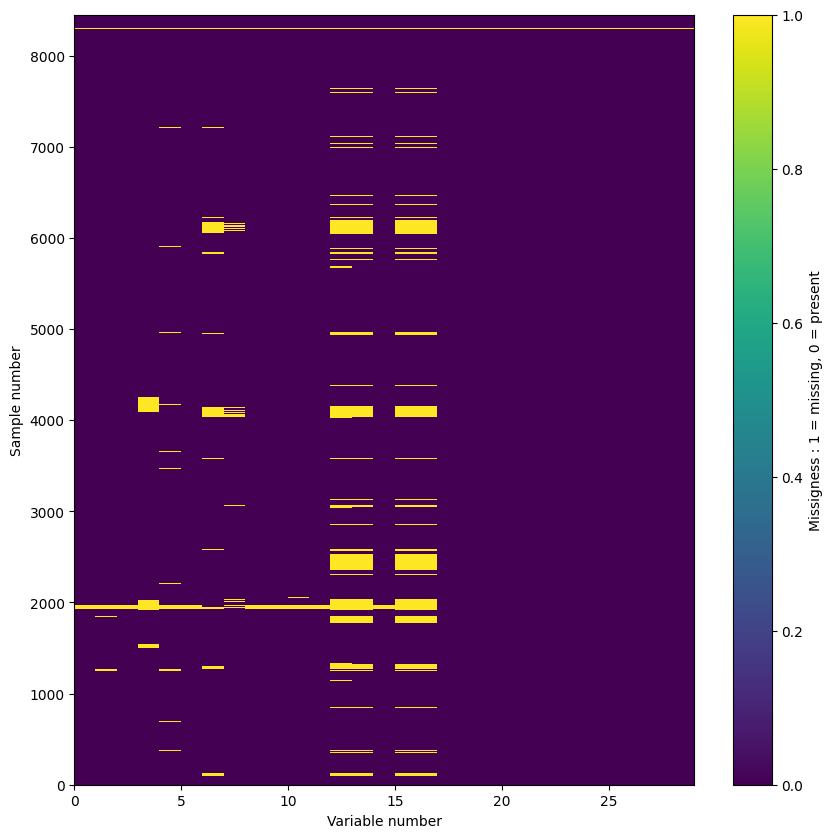

In [5]:
# check how the missing values are distributed in the data frame 

fig, ax, = plt.subplots(figsize = (10, 10))
im = ax.pcolor(df.isnull())
ax.set_xlabel('Variable number')
ax.set_ylabel('Sample number')
cbar = plt.colorbar(im)
cbar.set_label('Missigness : 1 = missing, 0 = present')

In [6]:
# check all the missing data and their timestamps 
all_missing = df.isnull().all(axis=1)

print("Rows with all measurements missing:", all_missing.sum())
print("Their timestamps:")
print(df.index[all_missing])

Rows with all measurements missing: 19
Their timestamps:
DatetimeIndex(['2016-02-15 02:00:00', '2016-03-09 14:00:00',
               '2016-03-09 15:00:00', '2016-03-09 16:00:00',
               '2016-09-26 12:59:00', '2016-12-25 14:59:00',
               '2016-12-25 17:59:00', '2016-12-25 18:59:00',
               '2016-12-25 19:59:00', '2016-12-25 20:59:00',
               '2016-12-25 21:59:00', '2016-12-25 22:59:00',
               '2016-12-25 23:59:00', '2016-12-26 00:59:00',
               '2016-12-26 01:59:00', '2016-12-26 02:59:00',
               '2016-12-26 03:59:00', '2016-12-26 04:59:00',
               '2016-12-26 05:59:00'],
              dtype='datetime64[us]', name='date', freq=None)


In [7]:
# Checking for missing timestamps, dupilcates, and the order of the dataframe
print("Missing timestamps:", df.index.isnull().sum())
print("Repeated timestamps:", df.index.duplicated().sum())
print("Chronological order:", df.index.is_monotonic_increasing)

# Time differences between successive observations
time_steps = df.index.to_series().diff()

print("\nMost common time intervals:")
print(time_steps.value_counts().head(10))

Missing timestamps: 0
Repeated timestamps: 0
Chronological order: True

Most common time intervals:
date
0 days 01:00:00    8447
0 days 00:59:00       1
Name: count, dtype: int64


In [8]:
# Inspecting the whole data set
df.describe(include = 'all').T

,count,mean,std,min,25%,50%,75%,max
Feed_comp_ag[%],8381.0,8.267362,2.938664,0.000000,7.328434,8.477114,10.182354,14.596026
Feed_comp_pb[%],8343.0,2.979655,1.239274,0.000000,2.428148,3.119387,3.790625,6.128111
Feed_rate_[ton/h],8379.0,418.995094,149.624304,0.024944,385.112273,455.725279,506.178545,653.131560
Feed_size_[um],8114.0,50.773689,12.918957,5.741424,43.604921,48.633342,56.774269,363.989699
Feed_solids[%],8268.0,31.422379,10.439748,0.000000,30.547733,34.420094,37.093372,46.547263
Feed_comp_au[%],8381.0,7.750329,2.891374,0.000000,6.715214,8.102608,9.770818,13.307563
Floatbank10_sulfate[g/ton],8047.0,10.884238,3.342648,0.000004,9.995040,11.003994,13.000684,21.888954
Floatbank10_xanthate [g/ton],8258.0,5.638528,1.845278,0.000016,5.395166,5.999366,6.561350,31.493331
Concentrate_ag[%],8381.0,11.056822,4.199159,0.000000,10.016452,11.818993,13.665562,24.480271
Concentrate_pb[%],8381.0,6.479724,2.318137,0.000000,6.290050,7.029023,7.772941,15.323901


array([<Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>], dtype=object)

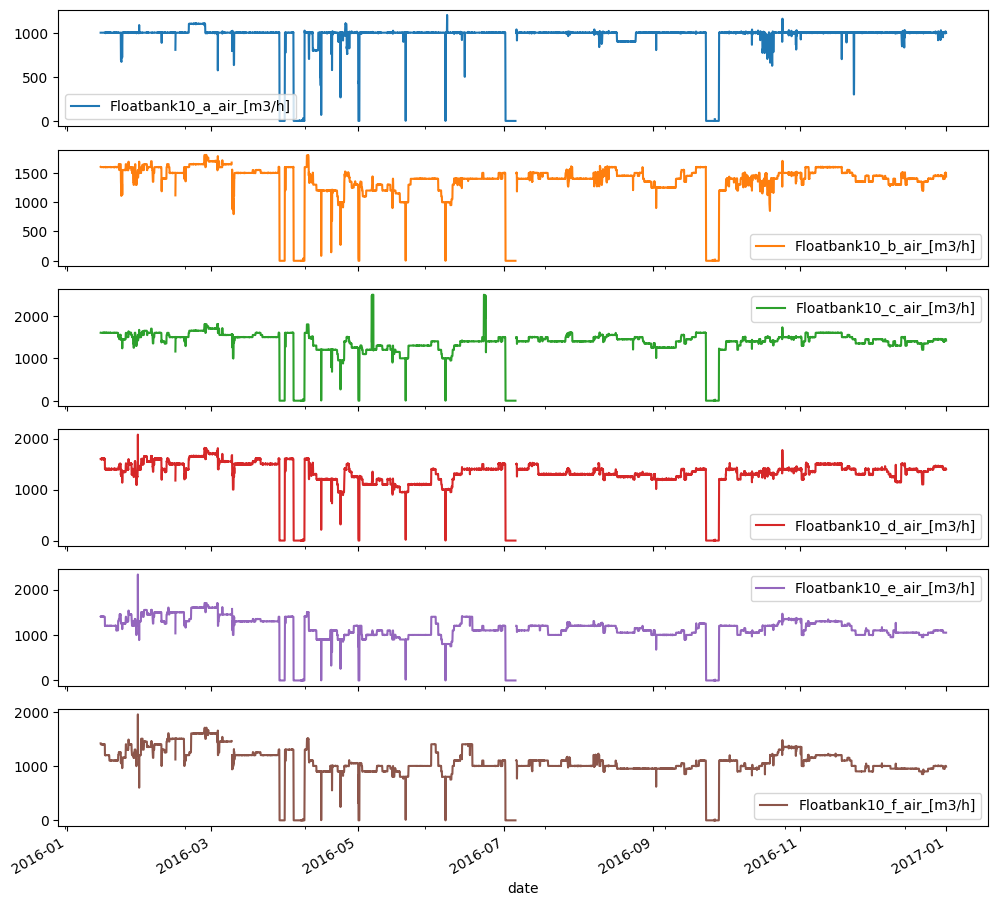

In [9]:
# Inspecting air flow to assess the negative readings 
air_columns = ['Floatbank10_a_air_[m3/h]','Floatbank10_b_air_[m3/h]', 'Floatbank10_c_air_[m3/h]', 'Floatbank10_d_air_[m3/h]', 'Floatbank10_e_air_[m3/h]', 'Floatbank10_f_air_[m3/h]']

df[air_columns].plot(subplots = True,  figsize = (12, 12))

In [10]:
# Negative readings in the six air-flow variables

print("Negative air-flow counts:")
print((df[air_columns] < 0).sum())

Negative air-flow counts:
Floatbank10_a_air_[m3/h]    279
Floatbank10_b_air_[m3/h]    391
Floatbank10_c_air_[m3/h]    375
Floatbank10_d_air_[m3/h]    397
Floatbank10_e_air_[m3/h]    397
Floatbank10_f_air_[m3/h]    397
dtype: int64


In [11]:
# Exact zero readings in the dataframe
zero_counts = (df == 0).sum()

print("\nZero-value counts:")
print(zero_counts[zero_counts > 0])


Zero-value counts:
Feed_comp_ag[%]         634
Feed_comp_pb[%]         634
Feed_solids[%]          634
Feed_comp_au[%]         634
Concentrate_ag[%]       755
Concentrate_pb[%]       755
Concentrate_solid[%]    755
Concentrate_au[%]       755
Recovery[%]             114
Tailings_pb[%]          675
dtype: int64


array([<Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>], dtype=object)

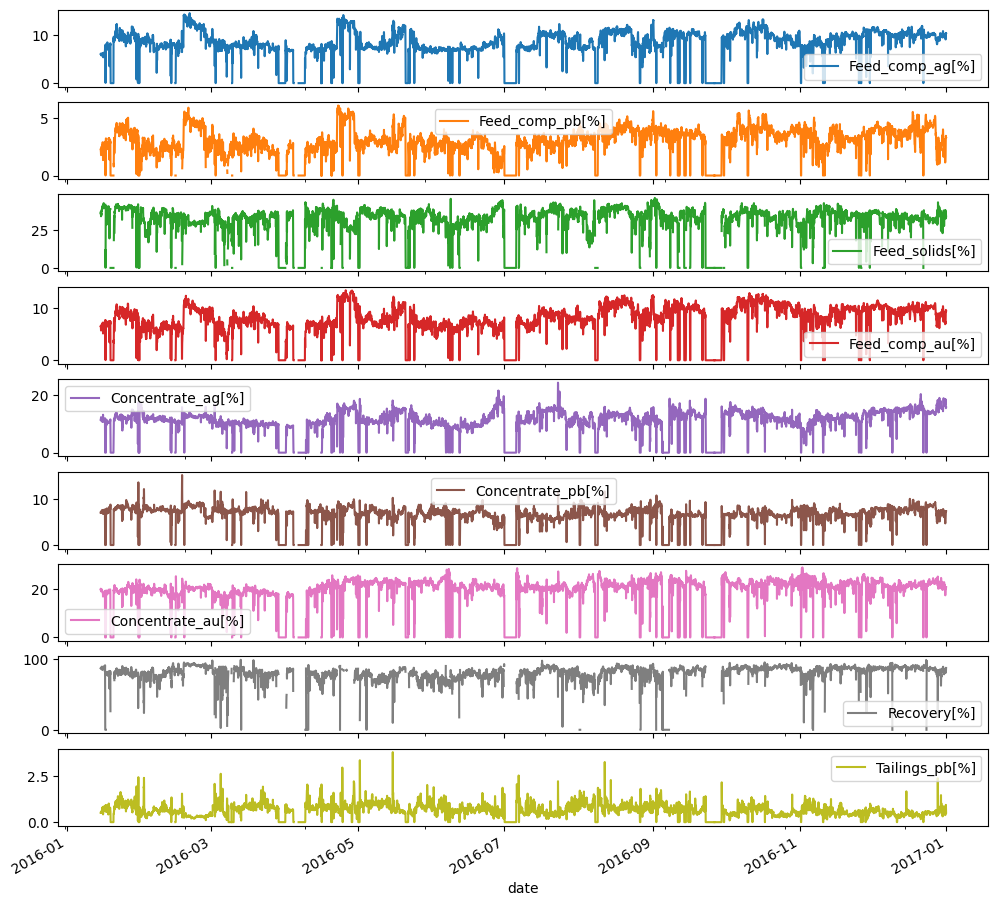

In [12]:
# Assess where these happens in each of the variables

zero_columns = ['Feed_comp_ag[%]', 'Feed_comp_pb[%]', 'Feed_solids[%]','Feed_comp_au[%]','Concentrate_ag[%]', 'Concentrate_pb[%]','Concentrate_au[%]','Recovery[%]', 'Tailings_pb[%]']

df[zero_columns].plot(subplots = True, figsize = (12, 12))

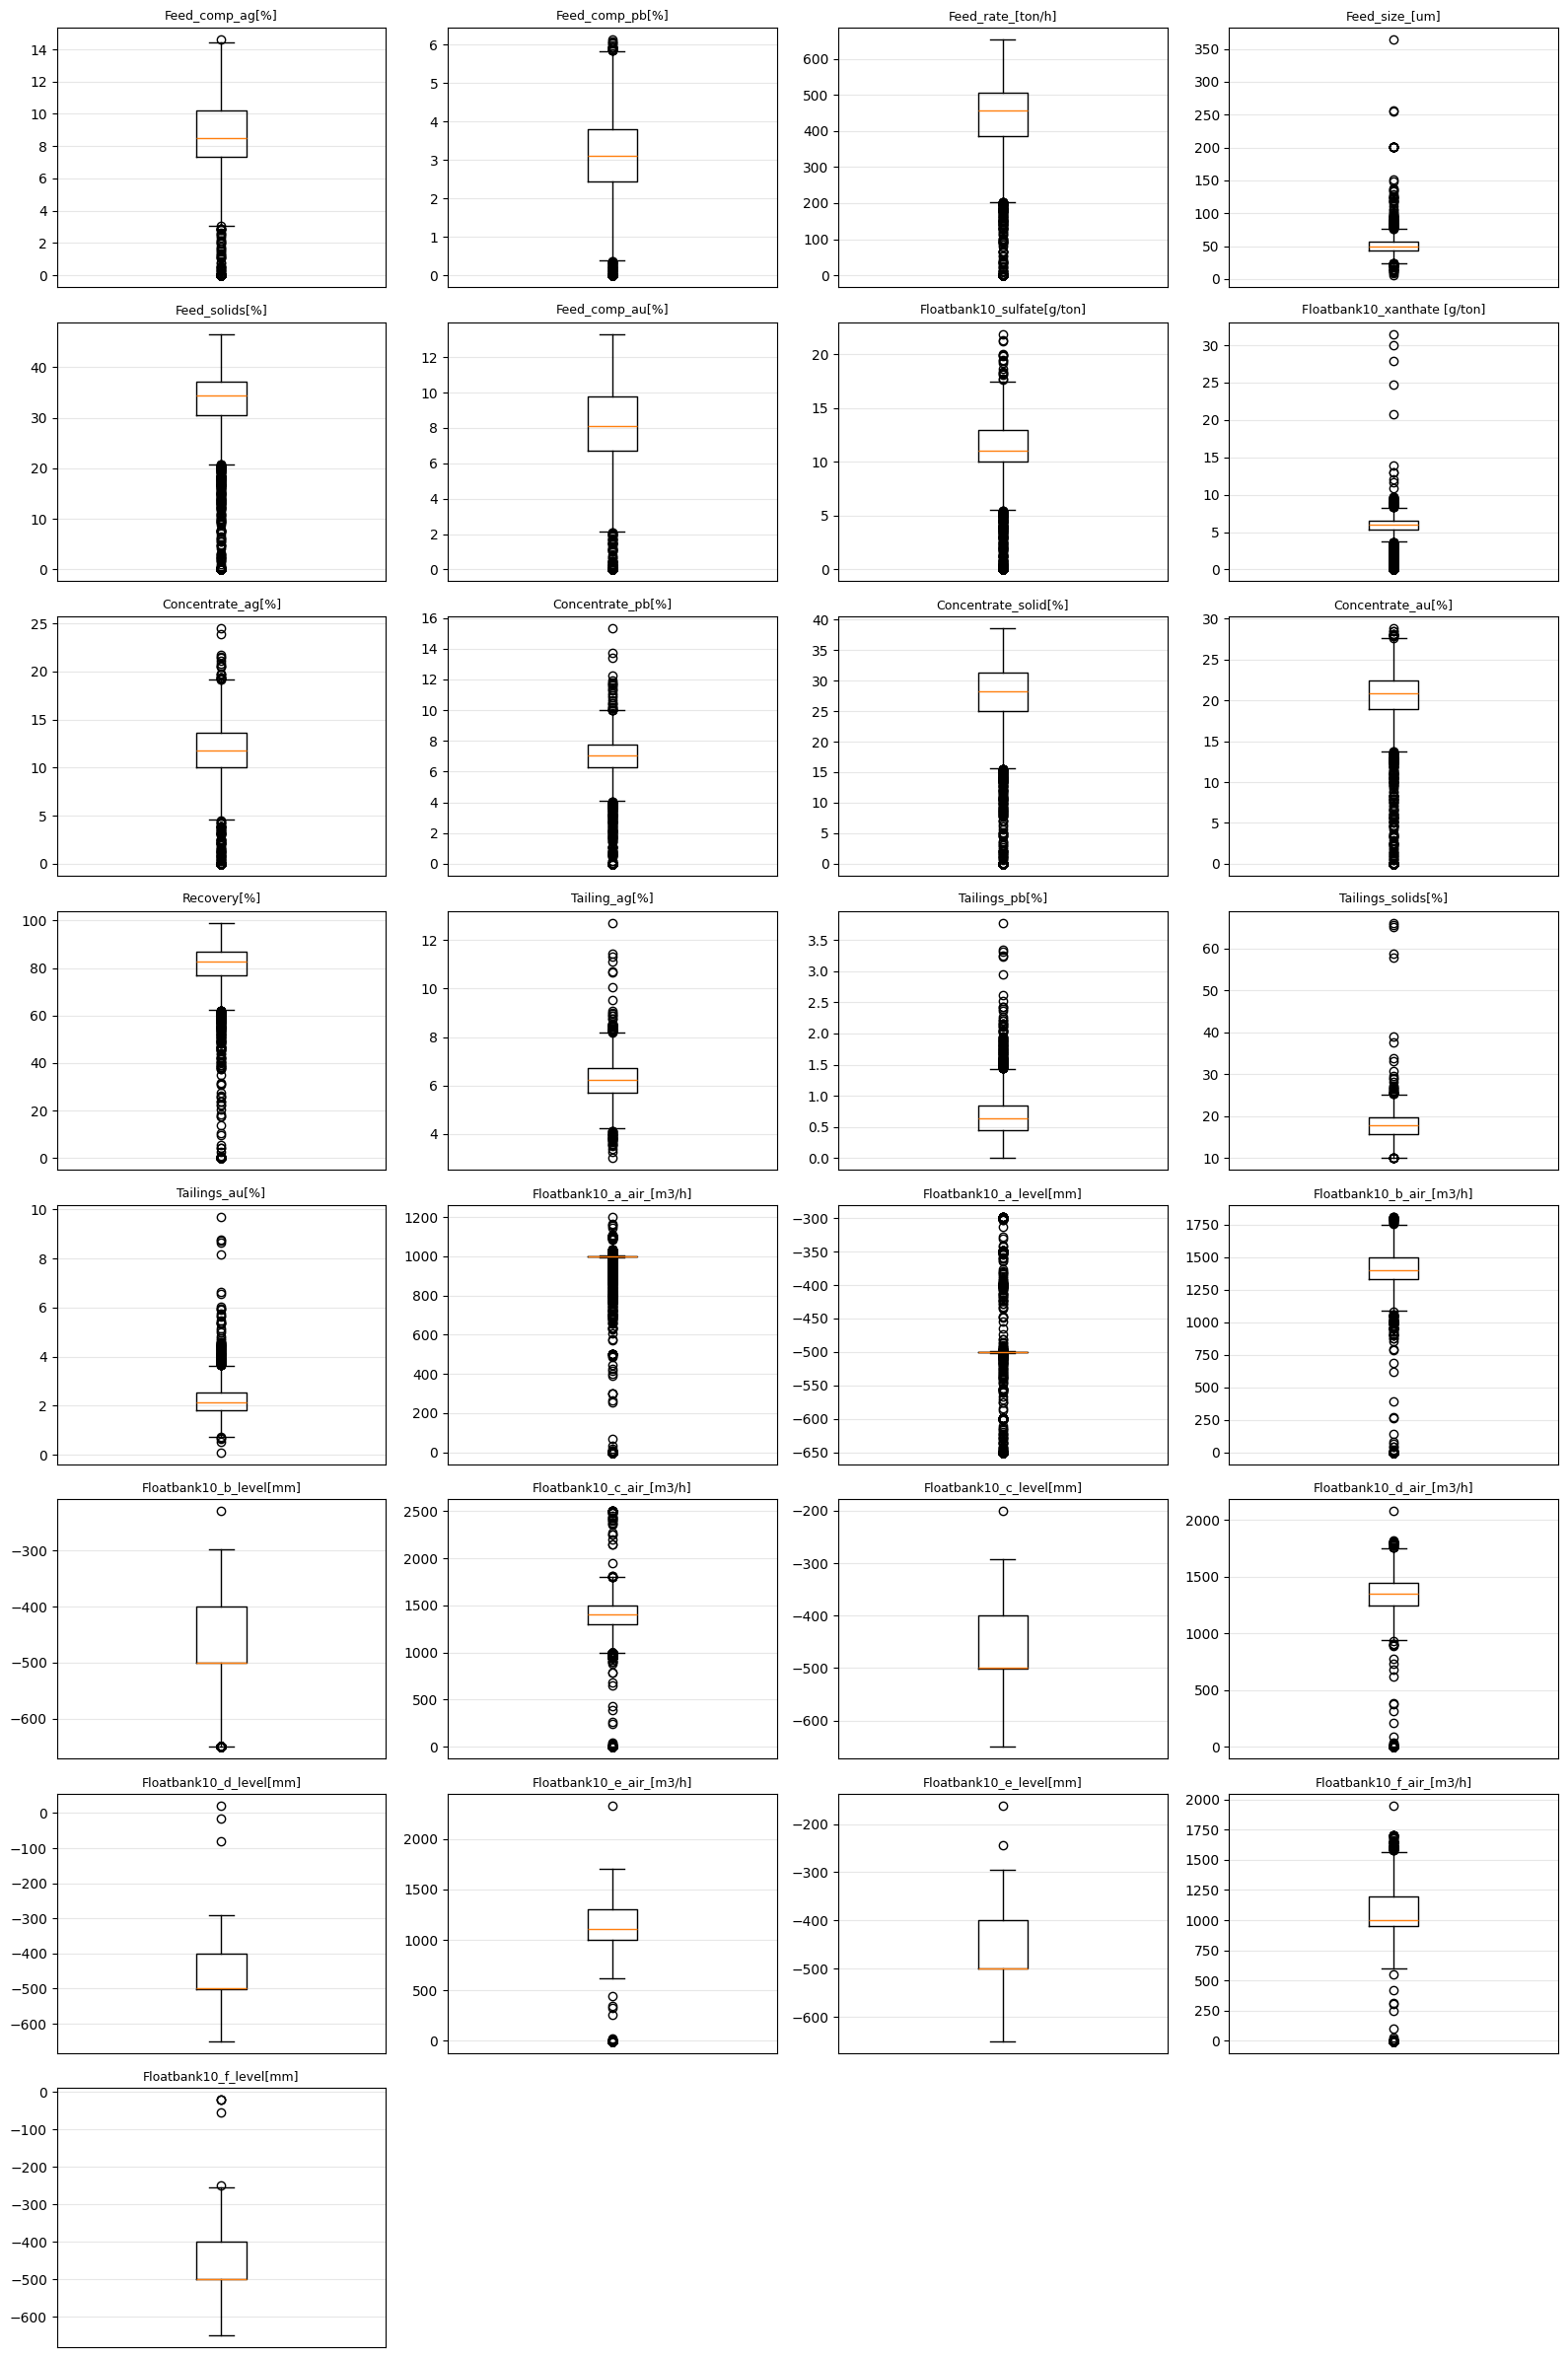

In [13]:
# check the box plot for each variables 
n_columns = 4
n_rows = math.ceil(len(df.columns) / n_columns)

fig, axes = plt.subplots(
    n_rows, n_columns,
    figsize=(16, 3 * n_rows)
)

axes = axes.flatten()

for ax, column in zip(axes, df.columns):
    ax.boxplot(df[column].dropna()) # do not include null values in the box-plot
    ax.set_title(column, fontsize=9)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)

# Hide unused plotting areas
for ax in axes[len(df.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Data cleaning


In [14]:
# Preserve the original dataframe
df_copy = df

In [15]:
# removing  recovery missed obeservations, since recovery is our prediction target and filling
# with estimated values can make the model learn for the inveted target 

df_copy.dropna(subset = 'Recovery[%]', inplace = True)

In [16]:
# replace the negative air flow rates with NaN, supplied air flow cannot physically be negative 

for column in air_columns:
    df_copy[column] = df_copy[column].mask(
        df_copy[column] < 0)

In [17]:
# flag observations outside grid-bearing slurry production 
invalid_feed = (
    (df_copy['Feed_comp_au[%]'] <= 0) | (df_copy['Feed_solids[%]'] <= 0) | (df_copy['Feed_rate_[ton/h]'] <= 0)
)

# filtering them out
df_copy = df_copy.loc[invalid_feed == False]

In [18]:
# model inputs: feed conditions and operaring variables 

input_columns = [
    column for column in df_copy.columns
    if column.startswith('Feed')
    or column.startswith('Floatbank10_')
]

# Inspect remaining missing inputs 
missing_inputs = df_copy[input_columns].isnull().sum()

print('Missing measuremnents in proposed inputs: ')
print(missing_inputs[missing_inputs > 0])

Missing measuremnents in proposed inputs: 
Feed_comp_pb[%]                  18
Feed_rate_[ton/h]                 1
Feed_size_[um]                  140
Feed_solids[%]                   53
Floatbank10_sulfate[g/ton]        7
Floatbank10_xanthate [g/ton]      2
Floatbank10_a_air_[m3/h]          2
Floatbank10_a_level[mm]           1
Floatbank10_b_air_[m3/h]          2
Floatbank10_b_level[mm]           1
Floatbank10_c_air_[m3/h]          2
Floatbank10_c_level[mm]           1
Floatbank10_d_air_[m3/h]          1
Floatbank10_e_air_[m3/h]          1
Floatbank10_f_air_[m3/h]          1
dtype: int64


In [19]:
# Assess complete-case removal
complete_inputs = df_copy[input_columns].notna().all(axis = 1)

print('Current rows:', len(df_copy))
print('Rows with complete inputs:', complete_inputs.sum())
print('Rows with missing inputs:', (complete_inputs == False).sum())

Current rows: 7367
Rows with complete inputs: 7165
Rows with missing inputs: 202


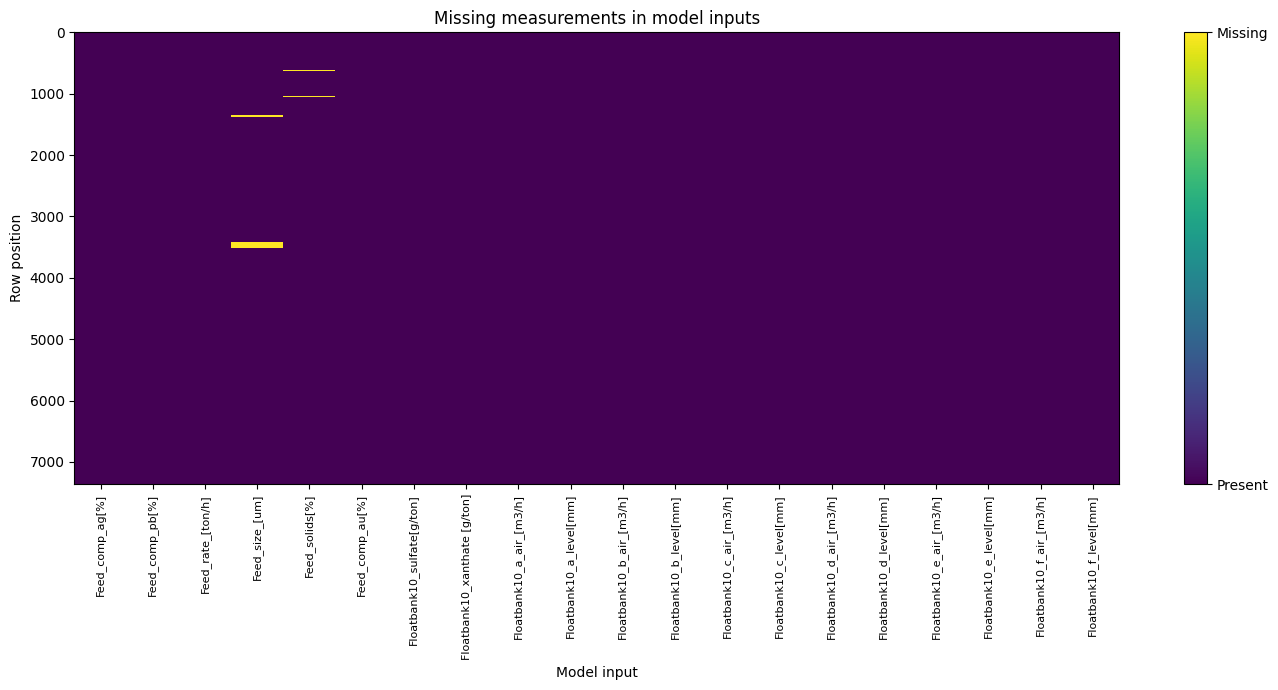

In [20]:
# check the pattern and distribution of these missing values 

fig, ax = plt.subplots(figsize = (14, 7))

heatmap = ax.imshow(
    df_copy[input_columns].isnull().to_numpy(),
    aspect = 'auto',
    interpolation = 'nearest',
    origin = 'upper',
    vmin = 0,
    vmax = 1
)

ax.set_xticks(range(len(input_columns)))
ax.set_xticklabels(input_columns, rotation = 90, fontsize = 8)

ax.set_xlabel('Model input')
ax.set_ylabel('Row position')
ax.set_title('Missing measurements in model inputs')

colourbar = fig.colorbar(heatmap, ax = ax, ticks = [0, 1])
colourbar.ax.set_yticklabels(['Present', 'Missing'])

plt.tight_layout()
plt.show()

In [21]:
# Remove observation with missing feed size or feed solids (better option than inventing data for model inputs)

df_copy = df_copy.dropna(
    subset = ['Feed_size_[um]', 'Feed_solids[%]']
)

In [22]:
# Identify inputs that still conatin missing measurements 

remaining_missing = df_copy[input_columns].isnull().sum()

for column in remaining_missing[remaining_missing > 0].index:
    print(f'{column}')
    print(df_copy.index[df_copy[column].isnull()])

Feed_comp_pb[%]
DatetimeIndex(['2016-01-31 10:00:00', '2016-02-27 19:00:00',
               '2016-02-27 20:00:00', '2016-03-25 08:00:00',
               '2016-06-27 22:59:00', '2016-06-27 23:59:00'],
              dtype='datetime64[us]', name='date', freq=None)
Floatbank10_sulfate[g/ton]
DatetimeIndex(['2016-07-18 14:59:00', '2016-09-02 06:59:00',
               '2016-09-13 21:59:00'],
              dtype='datetime64[us]', name='date', freq=None)
Floatbank10_a_air_[m3/h]
DatetimeIndex(['2016-06-06 13:59:00'], dtype='datetime64[us]', name='date', freq=None)
Floatbank10_b_air_[m3/h]
DatetimeIndex(['2016-06-06 13:59:00'], dtype='datetime64[us]', name='date', freq=None)
Floatbank10_c_air_[m3/h]
DatetimeIndex(['2016-06-06 13:59:00'], dtype='datetime64[us]', name='date', freq=None)
Floatbank10_d_air_[m3/h]
DatetimeIndex(['2016-06-06 13:59:00'], dtype='datetime64[us]', name='date', freq=None)
Floatbank10_e_air_[m3/h]
DatetimeIndex(['2016-06-06 13:59:00'], dtype='datetime64[us]', name='date', 

In [23]:
# Given how few missing observations remain, thus it is reasonable to remove them rather than
# making unsupported estimates 

df_copy = df_copy.dropna(subset = input_columns)

In [24]:
# Compare dataset sizes 
print('Original row:', len(df))
print('Cleaned rows:', len(df_copy))
print('Rows removed:', len(df) - len(df_copy))
print(f'Data retained: {(len(df_copy)/len(df)) * 100:.2f}%')

Original row: 7367
Cleaned rows: 7165
Rows removed: 202
Data retained: 97.26%


In [25]:
# confirm that model inputs have no missing values 

print('Remaining missing inputs: ')
print(df_copy[input_columns].isnull().sum())

Remaining missing inputs: 
Feed_comp_ag[%]                 0
Feed_comp_pb[%]                 0
Feed_rate_[ton/h]               0
Feed_size_[um]                  0
Feed_solids[%]                  0
Feed_comp_au[%]                 0
Floatbank10_sulfate[g/ton]      0
Floatbank10_xanthate [g/ton]    0
Floatbank10_a_air_[m3/h]        0
Floatbank10_a_level[mm]         0
Floatbank10_b_air_[m3/h]        0
Floatbank10_b_level[mm]         0
Floatbank10_c_air_[m3/h]        0
Floatbank10_c_level[mm]         0
Floatbank10_d_air_[m3/h]        0
Floatbank10_d_level[mm]         0
Floatbank10_e_air_[m3/h]        0
Floatbank10_e_level[mm]         0
Floatbank10_f_air_[m3/h]        0
Floatbank10_f_level[mm]         0
dtype: int64


In [26]:
# confirm recovery has no missing values 
print('Reamining missing recovery:', df_copy['Recovery[%]'].isnull().sum())

Reamining missing recovery: 0


In [27]:
# Comapre summary statistics (for the original data set and cleaned data set)

comparison = pd.concat(
    [
        df[input_columns + ['Recovery[%]']].describe().T,
        df_copy[input_columns + ['Recovery[%]']].describe().T
    ],
    axis = 1,
    keys = ['Original', 'Cleaned']
)

comparison

Original                                       \
                                count         mean         std         min   
Feed_comp_ag[%]                7367.0     8.930765    1.671847    0.047333   
Feed_comp_pb[%]                7349.0     3.202373    0.869811    0.008001   
Feed_rate_[ton/h]              7366.0   459.877787   88.987571    0.089999   
Feed_size_[um]                 7227.0    51.604681   12.182485   14.389224   
Feed_solids[%]                 7314.0    34.360903    4.941732    0.115461   
Feed_comp_au[%]                7367.0     8.385170    1.778747    0.033369   
Floatbank10_sulfate[g/ton]     7360.0    11.424902    2.399818    0.009081   
Floatbank10_xanthate [g/ton]   7365.0     6.040959    0.995143    0.000368   
Floatbank10_a_air_[m3/h]       7365.0   993.223733   47.551098  266.273641   
Floatbank10_a_level[mm]        7366.0  -474.733910   58.453248 -650.073062   
Floatbank10_b_air_[m3/h]       7365.0  1429.900415  145.425221  270.696463   
Floatbank10_b_level[mm]        7366.0  -453.749140   54.449167 -650.245277   
Floatbank10_c_air_[m3/h]       7365.0  1433.112033  159.728091  265.315357   
Floatbank10_c_level[mm]        7366.0  -455.002708   51.604169 -553.310893   
Floatbank10_d_air_[m3/h]       7366.0  1359.061574  153.161066  315.791949   
Floatbank10_d_level[mm]        7367.0  -455.800564   51.955785 -648.390665   
Floatbank10_e_air_[m3/h]       7366.0  1179.741899  175.826418  254.246738   
Floatbank10_e_level[mm]        7367.0  -450.963385   59.479655 -649.267537   
Floatbank10_f_air_[m3/h]       7366.0  1102.102374  188.553688  244.137561   
Floatbank10_f_level[mm]        7367.0  -451.380417   59.135599 -649.880981   
Recovery[%]                    7367.0    79.942445   13.194979    0.000000   

                                                                     \
                                      25%          50%          75%   
Feed_comp_ag[%]                  7.534596     8.845111    10.226491   
Feed_comp_pb[%]                  2.615496     3.205256     3.814522   
Feed_rate_[ton/h]              401.358981   474.995928   514.569602   
Feed_size_[um]                  44.056373    49.977367    57.331049   
Feed_solids[%]                  32.157872    34.945742    37.479877   
Feed_comp_au[%]                  6.995546     8.322869     9.822195   
Floatbank10_sulfate[g/ton]       9.999377    11.159892    13.003076   
Floatbank10_xanthate [g/ton]     5.566350     6.005211     6.610438   
Floatbank10_a_air_[m3/h]       999.153804   999.943272  1000.610411   
Floatbank10_a_level[mm]       -500.170454  -499.931749  -499.525091   
Floatbank10_b_air_[m3/h]      1362.068652  1421.520189  1501.516506   
Floatbank10_b_level[mm]       -500.031494  -499.297281  -400.073955   
Floatbank10_c_air_[m3/h]      1351.063673  1448.307723  1502.059045   
Floatbank10_c_level[mm]       -500.087486  -498.356717  -400.189339   
Floatbank10_d_air_[m3/h]      1289.581798  1389.968380  1476.240230   
Floatbank10_d_level[mm]       -500.141363  -498.130340  -400.275285   
Floatbank10_e_air_[m3/h]      1049.764901  1196.385429  1299.689823   
Floatbank10_e_level[mm]       -500.091905  -498.275280  -400.162749   
Floatbank10_f_air_[m3/h]       951.950517  1001.875955  1200.298597   
Floatbank10_f_level[mm]       -500.119239  -497.759681  -400.222109   
Recovery[%]                     77.109890    82.868277    87.072454   

                                          Cleaned                           \
                                      max   count         mean         std   
Feed_comp_ag[%]                 14.596026  7165.0     8.960756    1.673465   
Feed_comp_pb[%]                  5.940918  7165.0     3.210867    0.874251   
Feed_rate_[ton/h]              653.131560  7165.0   461.377151   85.428102   
Feed_size_[um]                 363.989699  7165.0    51.630011   12.172614   
Feed_solids[%]                  46.547263  7165.0    34.402122    4.932155   
Feed_comp_au[%]                 13.079582  7165.0     

## Model development and evaluation


In [28]:
# Arrange observation chronologically

model_data = df_copy.sort_index()

X = model_data[input_columns]
y = model_data['Recovery[%]']

# Define split boudaries
train_end = int(0.70 * len(X))
validation_end = int(0.85 * len(X))

# Split by row position
X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:validation_end]
X_test = X.iloc[validation_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:validation_end]
y_test = y.iloc[validation_end:]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

for name, subset in [
    ('Training', X_train),
    ('Validation', X_val),
    ('Test', X_test)
]:
    print(
        f'{name}: {len(subset)} rows | '
        f'{subset.index.min()} to {subset.index.max()}'
    )

Training: 5015 rows | 2016-01-15 00:00:00 to 2016-09-29 17:59:00
Validation: 1075 rows | 2016-09-29 18:59:00 to 2016-11-15 12:59:00
Test: 1075 rows | 2016-11-15 13:59:00 to 2016-12-31 23:59:00


### Candidate models


In [29]:
# Define the model (Linear regression)
linear_model = LinearRegression()

# Learn coefficients from trating inputs and measured recovery
linear_model.fit(X_train_scaled, y_train)

# Predict recovery for validation observation 
y_val_pred_linear = linear_model.predict(X_val_scaled)

# Define candidate models (k-nearest neighbors)
knn_models = {
    'KNN_5_uniform': KNeighborsRegressor(
        n_neighbors = 5, weights = 'uniform'
    ),
    'KNN_15_uniform': KNeighborsRegressor(
        n_neighbors = 15, weights = 'uniform'
    ),
    'KNN_30_uniform': KNeighborsRegressor(
        n_neighbors = 30, weights = 'uniform'
    ),
    'KNN_15_distance': KNeighborsRegressor(
        n_neighbors = 15, weights = 'distance'
    )
}

knn_val_predictions = {}

# Fit each candidate and predict validation recovery
for name, model in knn_models.items():
    model.fit(X_train_scaled, y_train)
    knn_val_predictions[name] = model.predict(X_val_scaled)


# Candidate hidden layers (neural_network)
nn_structures = {
    'NN_16': (16,),
    'NN_32': (32,),
    'NN_32_16': (32, 16)
}

nn_models = {}
nn_val_predictions = {}

for name, structure in nn_structures.items():
    model = MLPRegressor(
        hidden_layer_sizes = structure, 
        activation = 'relu', 
        max_iter = 5000,
        shuffle = False,
        random_state = 42 # for consistant results 
    )
    
    model.fit(X_train_scaled, y_train)
    
    nn_models[name] = model
    nn_val_predictions[name] = model.predict(X_val_scaled)

_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


### Validation and model selection


In [30]:
validation_predictions = {
    'Linear regression': y_val_pred_linear,
    **knn_val_predictions, 
    **nn_val_predictions
}

validation_results = pd.DataFrame([
    {'Model': name, 
    'Validation R^2': r2_score(y_val, predictions)} for name, predictions in validation_predictions.items()]).set_index('Model').sort_values('Validation R^2', ascending = False)

validation_results

,Validation R^2
Model,
Linear regression,0.450332
KNN_15_uniform,0.076912
KNN_15_distance,0.076442
KNN_5_uniform,-0.075823
KNN_30_uniform,-0.111015
NN_32,-2.565741
NN_16,-3.985308
NN_32_16,-8.447519


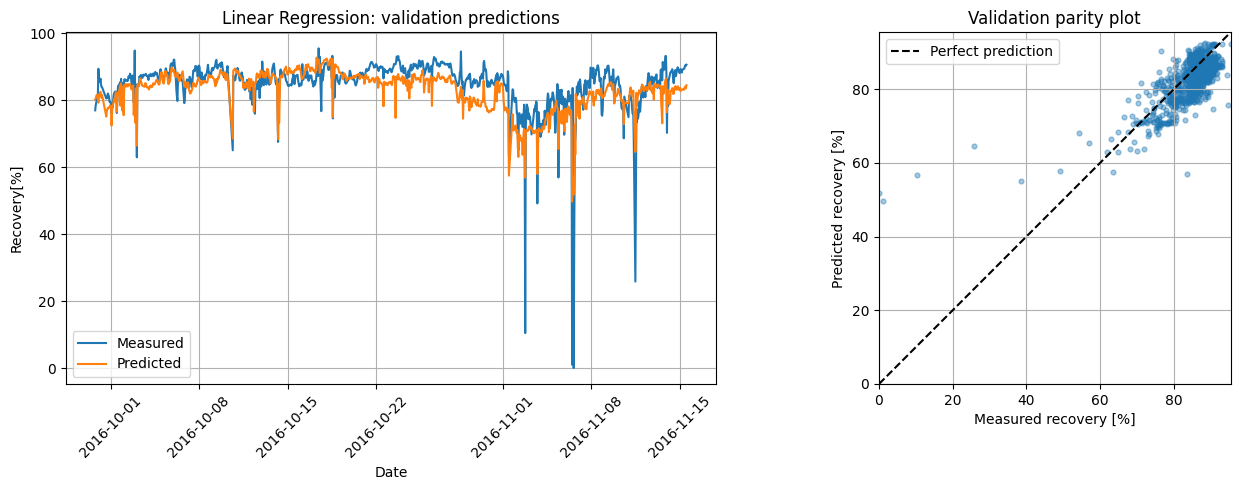

In [31]:
# model to advance - Linear regression 

fig, axes = plt.subplots(1, 2, figsize = (14, 5))

# validation recovery over time 
axes[0].plot(
    y_val.index, y_val,
    label = 'Measured'
)

axes[0].plot(
    y_val.index, y_val_pred_linear,
    label = 'Predicted'
)

axes[0].set_xlabel('Date')
axes[0].set_ylabel('Recovery[%]')
axes[0].set_title('Linear Regression: validation predictions')
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True)
axes[0].legend()

# parity plot

axes[1].scatter(y_val, y_val_pred_linear, s = 12, alpha = 0.4)

lower = min(y_val.min(), y_val_pred_linear.min())
upper = max(y_val.max(), y_val_pred_linear.max())

axes[1].plot(
    [lower, upper], [lower, upper], 'k--', label = 'Perfect prediction'
)

axes[1].set_xlim(lower, upper)
axes[1].set_ylim(lower, upper)
axes[1].set_aspect('equal', adjustable = 'box')
axes[1].set_xlabel('Measured recovery [%]')
axes[1].set_ylabel('Predicted recovery [%]')
axes[1].set_title('Validation parity plot')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

### Test evaluation and permutation importance


In [32]:
selected_model = linear_model 

y_test_pred = selected_model.predict(X_test_scaled)
test_r2 = r2_score(y_test, y_test_pred)

print(f'Validation R^2: {r2_score(y_val, y_val_pred_linear):.4f}')
print(f'Test R^2: {test_r2:4f}')

Validation R^2: 0.4503
Test R^2: -1.033836


In [ ]:
# Selected linear model coefficients in both input scales
coefficient_table = pd.DataFrame({
    'Standardised coefficient': selected_model.coef_,
    'Original-unit coefficient': selected_model.coef_ / scaler.scale_
}, index=X_train.columns)

print(f'Standardised-input intercept: {selected_model.intercept_:.6f}')
original_intercept = selected_model.intercept_ - np.sum(selected_model.coef_ * scaler.mean_ / scaler.scale_)
print(f'Original-unit intercept: {original_intercept:.6f}')
display(coefficient_table)


Standardised-input intercept: 77.837119
Original-unit intercept: 46.299889


,Standardised coefficient,Original-unit coefficient
Feed_comp_ag[%],2.903941,1.716991
Feed_comp_pb[%],-1.712295,-1.996025
Feed_rate_[ton/h],-0.598462,-0.006825
Feed_size_[um],0.800994,0.068695
Feed_solids[%],0.981145,0.188853
Feed_comp_au[%],2.693519,1.601261
Floatbank10_sulfate[g/ton],-0.689454,-0.299625
Floatbank10_xanthate [g/ton],1.943658,1.930688
Floatbank10_a_air_[m3/h],-0.180817,-0.003952
Floatbank10_a_level[mm],-0.202882,-0.003741


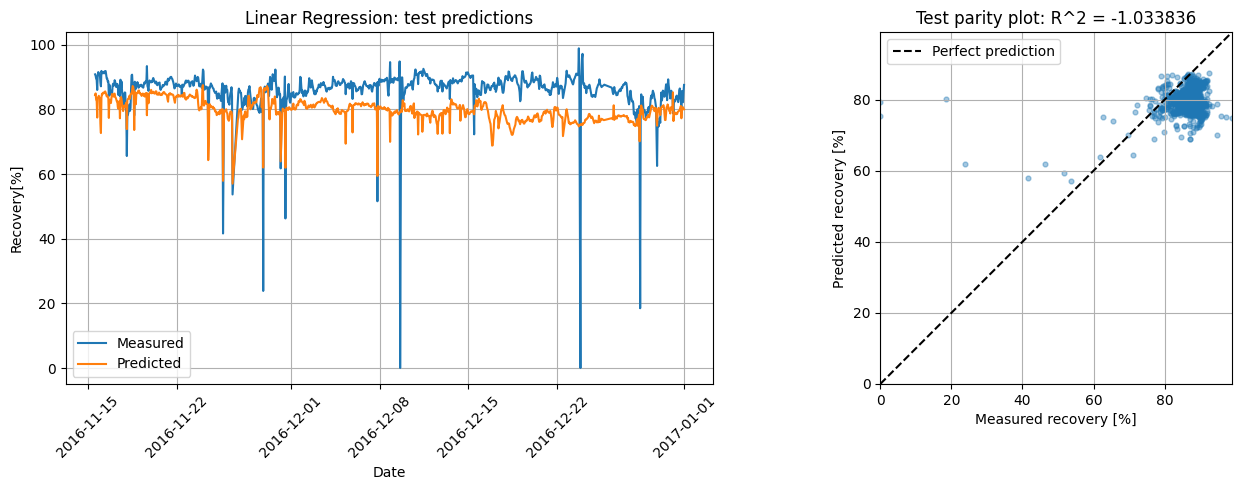

In [34]:
# inspect test predictions 
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

# Test recovery over time 
axes[0].plot(
    y_test.index, y_test,
    label = 'Measured'
)

axes[0].plot(
    y_test.index, y_test_pred,
    label = 'Predicted'
)

axes[0].set_xlabel('Date')
axes[0].set_ylabel('Recovery[%]')
axes[0].set_title('Linear Regression: test predictions')
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True)
axes[0].legend()

# parity plot

axes[1].scatter(y_test, y_test_pred, s = 12, alpha = 0.4)

lower = min(y_test.min(), y_test_pred.min())
upper = max(y_test.max(), y_test_pred.max())

axes[1].plot(
    [lower, upper], [lower, upper], 'k--', label = 'Perfect prediction'
)

axes[1].set_xlim(lower, upper)
axes[1].set_ylim(lower, upper)
axes[1].set_aspect('equal', adjustable = 'box')
axes[1].set_xlabel('Measured recovery [%]')
axes[1].set_ylabel('Predicted recovery [%]')
axes[1].set_title(f'Test parity plot: R^2 = {test_r2:4f}')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

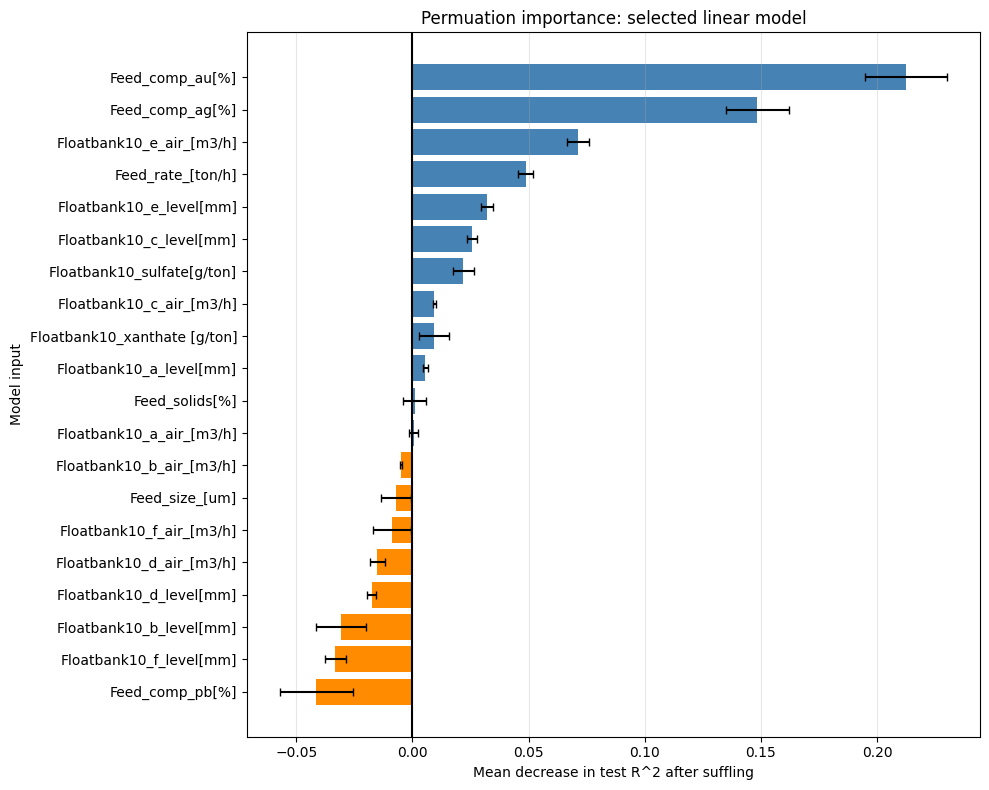

In [35]:
importance = permutation_importance(
    selected_model,
    X_test_scaled,
    y_test,
    n_repeats = 20,
    random_state = 42
)

# sort inputs by mean importance
order = np.argsort(importance.importances_mean)

means = importance.importances_mean[order]
stds = importance.importances_std[order]
names = X_train.columns.to_numpy()[order]

fig, ax = plt.subplots(figsize = (10, 8))

ax.barh(names, means, xerr = stds, capsize = 3, color = ['steelblue' if value >= 0 else 'darkorange' for value in means])

ax.axvline(0, color = 'black')
ax.set_xlabel('Mean decrease in test R^2 after suffling')
ax.set_ylabel('Model input')
ax.set_title('Permuation importance: selected linear model')
ax.grid(axis = 'x', alpha = 0.3)

plt.tight_layout()
plt.show()

## Operating-condition optimisation


In [36]:
# Feed consitions specified 
fixed_feed = {
    'Feed_comp_ag[%]': 7.54,
    'Feed_comp_pb[%]': 1.0,
    'Feed_rate_[ton/h]': 600.0,
    'Feed_size_[um]': 25.0,
    'Feed_solids[%]': 30.0,
    'Feed_comp_au[%]': 9.8
}

# Operating varibales to optimise 
Operating_columns = [column for column in X_train.columns if column.startswith('Floatbank10_')]

# Allowable range from the original training inputs 
Operating_bounds = pd.DataFrame({
    'Lower_bound': X_train[Operating_columns].min(),
    'Upper_bound': X_train[Operating_columns].max()
})

Operating_bounds

,Lower_bound,Upper_bound
Floatbank10_sulfate[g/ton],0.260698,21.307168
Floatbank10_xanthate [g/ton],0.125279,9.703448
Floatbank10_a_air_[m3/h],401.051413,1200.659653
Floatbank10_a_level[mm],-629.371084,-298.195267
Floatbank10_b_air_[m3/h],899.399448,1809.194008
Floatbank10_b_level[mm],-556.487015,-298.488688
Floatbank10_c_air_[m3/h],876.919757,2499.129174
Floatbank10_c_level[mm],-553.310893,-295.103390
Floatbank10_d_air_[m3/h],890.828482,1817.199290
Floatbank10_d_level[mm],-648.390665,-299.486309


In [37]:
# Convert fitted coefficients to original input units 
original_coefficients = pd.Series(selected_model.coef_ / scaler.scale_, index = X_train.columns)

# Coefficients for the operating varables 
Operating_coefficients = original_coefficients.loc[Operating_columns]

bounds = list(zip(
    Operating_bounds.loc[Operating_columns, 'Lower_bound'],
    Operating_bounds.loc[Operating_columns, 'Upper_bound']
))

# Maximise recovery by minising its negavtive contribution 
result = linprog(
    c = - Operating_coefficients.to_numpy(),
    bounds = bounds,
)

if not result.success:
    raise RuntimeError(result.message)

optimal_settings = pd.Series(result.x, index = Operating_columns, name = 'Optimal setting')

optimal_settings

Floatbank10_sulfate[g/ton]         0.260698
Floatbank10_xanthate [g/ton]       9.703448
Floatbank10_a_air_[m3/h]         401.051413
Floatbank10_a_level[mm]         -629.371084
Floatbank10_b_air_[m3/h]        1809.194008
Floatbank10_b_level[mm]         -298.488688
Floatbank10_c_air_[m3/h]         876.919757
Floatbank10_c_level[mm]         -553.310893
Floatbank10_d_air_[m3/h]        1817.199290
Floatbank10_d_level[mm]         -299.486309
Floatbank10_e_air_[m3/h]         749.422599
Floatbank10_e_level[mm]         -559.504267
Floatbank10_f_air_[m3/h]        1706.307502
Floatbank10_f_level[mm]         -299.651854
Name: Optimal setting, dtype: float64

In [38]:
# Assemble all twenty inputs in the training column order 
optimal_input = X_train.iloc[[0]]

for column, value in fixed_feed.items():
    optimal_input[column] = value

optimal_input.loc[:, Operating_columns] = [optimal_settings.to_numpy()]

# Apply the existing training scaler and predict 
optimal_recovery = selected_model.predict(
    scaler.transform(optimal_input)
)[0]

# Define typical operation using training median settings 
typical_input = optimal_input

typical_input.loc[:, Operating_columns] = [X_train[Operating_columns].median().to_numpy()]

typical_recovery = selected_model.predict(
    scaler.transform(typical_input)
)[0]

# Display bounds, typical settings and optimum

settings_comparison = Operating_bounds
settings_comparison['Typical setting'] = (X_train[Operating_columns].median())
settings_comparison['Optimal setting'] = optimal_settings

display(settings_comparison)

print(f"Typical predicted recovery: {typical_recovery:.2f}%")
print(f"Optimal predicted recovery: {optimal_recovery:.2f}%")
print("Predicted improvement: ", f"{optimal_recovery - typical_recovery:.2f} percentage points")

,Lower_bound,Upper_bound,Typical setting,Optimal setting
Floatbank10_sulfate[g/ton],0.260698,21.307168,10.998601,0.260698
Floatbank10_xanthate [g/ton],0.125279,9.703448,5.998909,9.703448
Floatbank10_a_air_[m3/h],401.051413,1200.659653,999.974010,401.051413
Floatbank10_a_level[mm],-629.371084,-298.195267,-499.932362,-629.371084
Floatbank10_b_air_[m3/h],899.399448,1809.194008,1407.632896,1809.194008
Floatbank10_b_level[mm],-556.487015,-298.488688,-499.584896,-298.488688
Floatbank10_c_air_[m3/h],876.919757,2499.129174,1449.214820,876.919757
Floatbank10_c_level[mm],-553.310893,-295.103390,-499.060233,-553.310893
Floatbank10_d_air_[m3/h],890.828482,1817.199290,1313.848234,1817.199290
Floatbank10_d_level[mm],-648.390665,-299.486309,-499.183126,-299.486309


Typical predicted recovery: 76.02%
Optimal predicted recovery: 117.94%
Predicted improvement:  41.93 percentage points


In [39]:
# assesing whether the specified feed is represented in training data 

feed_columns = list(fixed_feed)

feed_check = pd.DataFrame({
    'Specified feed': pd.Series(fixed_feed),
    'Training minimum': X_train[feed_columns].min(),
    "Training 25%": X_train[feed_columns].quantile(0.25),
    "Training median": X_train[feed_columns].median(),
    "Training 75%": X_train[feed_columns].quantile(0.75),
    "Training maximum": X_train[feed_columns].max()
})

feed_check['Within training range'] = ((feed_check['Specified feed'] >= feed_check['Training minimum']) & (feed_check['Specified feed'] <= feed_check['Training maximum']))

feed_check

,Specified feed,Training minimum,Training 25%,Training median,Training 75%,Training maximum,Within training range
Feed_comp_ag[%],7.54,0.047333,7.325354,8.078930,9.959611,14.596026,True
Feed_comp_pb[%],1.00,0.008001,2.478466,2.981360,3.609561,5.940918,True
Feed_rate_[ton/h],600.00,0.089999,427.435295,498.629230,529.908352,653.131560,True
Feed_size_[um],25.00,14.389224,47.964157,54.669674,59.178102,201.009933,True
Feed_solids[%],30.00,0.115461,32.049490,35.096101,38.007439,46.547263,True
Feed_comp_au[%],9.80,0.033369,6.744834,7.678156,9.093342,13.079582,True


In [40]:
# Reuse the training scaler's parameters for the six feed inputs

feed_columns = list(fixed_feed)

feed_mean = pd.Series(scaler.mean_, index=X_train.columns).loc[feed_columns]

feed_scale = pd.Series(scaler.scale_, index=X_train.columns).loc[feed_columns]

training_feed_scaled = (X_train[feed_columns] - feed_mean) / feed_scale

specified_feed_scaled = (pd.Series(fixed_feed).loc[feed_columns] - feed_mean) / feed_scale

# Distance across all six feed measurements 
feed_distances = np.sqrt(((training_feed_scaled - specified_feed_scaled) ** 2).sum(axis=1))

nearest_dates = feed_distances.sort_values().head(5).index

nearest_feed = X_train.loc[nearest_dates, feed_columns]
nearest_feed["Standardised distance"] = feed_distances.loc[nearest_dates]

nearest_feed

,Feed_comp_ag[%],Feed_comp_pb[%],Feed_rate_[ton/h],Feed_size_[um],Feed_solids[%],Feed_comp_au[%],Standardised distance
date,,,,,,,
2016-04-09 17:00:00,7.160939,2.104467,525.220575,26.823460,29.199659,6.417814,2.554623
2016-03-15 23:00:00,7.391697,1.969872,500.053684,37.364839,29.842254,6.724205,2.655948
2016-03-16 00:00:00,7.126200,1.785457,500.250348,37.323699,30.418020,6.522771,2.666758
2016-03-15 21:00:00,7.407080,1.951593,500.168019,37.997160,30.252767,6.728149,2.666961
2016-03-16 01:00:00,7.283698,1.761157,500.038622,37.154154,29.953071,6.460636,2.671612
